<a href="https://colab.research.google.com/github/CoralsINPA/RedSeaCoralIdentifier/blob/claude%2Ffervent-cerf-h6mv5z/Millepora_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Path to the completed run's output folder
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
csv_path = os.path.join(v2_dir, 'v2_tiered_labels.csv')

df = pd.read_csv(csv_path)

# --- 1. Predictions of Millepora ---
millepora_pred = df[df['predicted_genus'] == 'Millepora']
millepora_accepted = millepora_pred[millepora_pred['tier'] == 'auto_accept']  # Confident >= 0.85
millepora_review = millepora_pred[millepora_pred['tier'] == 'expert_review']   # Uncertain < 0.85 (FP risk)

# --- 2. Missed Millepora (False Negative risk) ---
# The model chose another genus, but Millepora was the runner-up
millepora_fn = df[(df['predicted_genus'] != 'Millepora') & (df['runner_up'] == 'Millepora')]

print("=" * 45)
print("MILLEPORA OVERVIEW")
print("=" * 45)
print(f"Total corals predicted as Millepora: {len(millepora_pred)}")
print(f"  • Confident (>= 0.85, Auto-accepted): {len(millepora_accepted)}")
print(f"  • Uncertain (< 0.85, Potential False Positives): {len(millepora_review)}")
print(f"Potential False Negatives (Millepora was runner-up): {len(millepora_fn)}")

print("\n--- When model chose Millepora, what was the #2 choice? ---")
print(millepora_pred['runner_up'].value_counts().head(5))

print("\n--- What was chosen when Millepora was the #2 choice? (False Negatives) ---")
print(millepora_fn['predicted_genus'].value_counts().head(5))

MILLEPORA OVERVIEW
Total corals predicted as Millepora: 790
  • Confident (>= 0.85, Auto-accepted): 372
  • Uncertain (< 0.85, Potential False Positives): 418
Potential False Negatives (Millepora was runner-up): 267

--- When model chose Millepora, what was the #2 choice? ---
runner_up
Echinopora     196
Seriatopora    165
Sinularia      149
Pavona         108
Stylophora      32
Name: count, dtype: int64

--- What was chosen when Millepora was the #2 choice? (False Negatives) ---
predicted_genus
Pavona         56
Echinopora     56
Seriatopora    23
Stylophora     17
Sarcophyton    16
Name: count, dtype: int64


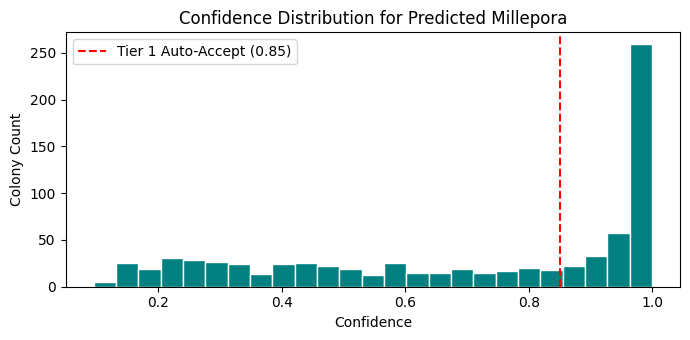

In [ ]:
plt.figure(figsize=(7, 3.5))
plt.hist(millepora_pred['confidence'], bins=25, color='teal', edgecolor='white')
plt.axvline(0.85, color='red', linestyle='--', label='Tier 1 Auto-Accept (0.85)')
plt.xlabel('Confidence')
plt.ylabel('Colony Count')
plt.title('Confidence Distribution for Predicted Millepora')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ===================================================
# Create PDF with all Millepora with confidence >0.85
# ===================================================

import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pycocotools.mask as mask_util
from tqdm import tqdm

# --- 1. Paths ---
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
data_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking/data_all'
json_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/json'
pdf_output_path = os.path.join(v2_dir, 'Millepora_confident_ge_0.85.pdf')

# --- 2. Filter Confident Millepora ---
df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))
confident_millepora = df[
    (df['predicted_genus'] == 'Millepora') &
    (df['confidence'] >= 0.85)
].sort_values('confidence', ascending=False).reset_index(drop=True)

print(f"Total confident Millepora to export: {len(confident_millepora)}")

# --- 3. Crop and Mask Helper Functions ---
def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return mask_util.decode(rle).astype(bool)

def get_masked_crop(img, bbox, rle=None, padding_pct=0.05):
    x, y, w, h = map(int, bbox)
    pad_w = int(w * padding_pct)
    pad_h = int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)

    if rle is not None:
        mask = decode_rle(rle)
        if mask.shape != img.shape[:2]:
            mask = cv2.resize(mask.astype('uint8'), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
        masked_img = img.copy()
        masked_img[~mask] = 0
        crop = masked_img[y1:y2, x1:x2]
    else:
        crop = img[y1:y2, x1:x2]

    if crop.size == 0:
        return None
    return crop

# --- 4. Build Multi-Page PDF ---
ROWS = 4
COLS = 3
PER_PAGE = ROWS * COLS
total_items = len(confident_millepora)
num_pages = int(np.ceil(total_items / PER_PAGE))

# Cache loaded images across consecutive annotations from the same image
current_img_name = None
cached_img = None

with PdfPages(pdf_output_path) as pdf:
    for page_idx in tqdm(range(num_pages), desc="Generating PDF pages"):
        fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 16))
        axes = axes.flatten()

        start_idx = page_idx * PER_PAGE
        end_idx = min(start_idx + PER_PAGE, total_items)
        page_df = confident_millepora.iloc[start_idx:end_idx]

        for i, (_, row) in enumerate(page_df.iterrows()):
            ax = axes[i]
            img_name = row['image_name']

            # Load full image only if different from cached
            if img_name != current_img_name:
                img_path = os.path.join(data_path, img_name)
                current_img_name = img_name
                raw_img = cv2.imread(img_path)
                if raw_img is not None:
                    cached_img = cv2.cvtColor(cv2.resize(raw_img, (2560, 1920)), cv2.COLOR_BGR2RGB)
                else:
                    cached_img = None

            if cached_img is None:
                ax.axis('off')
                continue

            bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']

            # Retrieve mask from corresponding JSON
            json_path = os.path.join(json_dir, os.path.splitext(img_name)[0] + '.json')
            rle = None
            if os.path.exists(json_path):
                with open(json_path, 'r') as f:
                    jdata = json.load(f)
                for anno in jdata['annotations']:
                    if anno['id'] == row['coral_id']:
                        rle = anno['segmentation']
                        break

            crop = get_masked_crop(cached_img, bbox, rle)

            if crop is None:
                ax.axis('off')
                continue

            ax.imshow(crop)
            ax.set_title(
                f"Conf: {row['confidence']:.3f} | #2: {row['runner_up']}\n{img_name} (ID: {row['coral_id']})",
                fontsize=8,
                pad=3
            )
            ax.axis('off')

        # Turn off empty subplots on the last page
        for j in range(len(page_df), PER_PAGE):
            axes[j].axis('off')

        fig.suptitle(
            f"Millepora (Conf >= 0.85) — Page {page_idx + 1} of {num_pages}",
            fontsize=13,
            y=0.99
        )
        plt.tight_layout()
        pdf.savefig(fig, dpi=120)
        plt.close(fig)

print(f"\nPDF saved successfully to:\n{pdf_output_path}")

Total confident Millepora to export: 372


Generating PDF pages: 100%|██████████| 31/31 [06:44<00:00, 13.04s/it]



PDF saved successfully to:
/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/Millepora_confident_ge_0.85.pdf


In [ ]:
import os
import cv2
import pandas as pd
import numpy as np

# 1. Paths
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
data_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking/data_all'

# 2. Load and filter confident Millepora directly
df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))
confident_millepora = df[
    (df['predicted_genus'] == 'Millepora') &
    (df['confidence'] >= 0.85)
].copy().reset_index(drop=True)

print(f"Loaded {len(confident_millepora)} confident Millepora records.")

# 3. Calculate sharpness scores
sharpness_scores = []

for _, row in confident_millepora.iterrows():
    img_name = row['image_name']
    img_path = os.path.join(data_path, img_name)
    raw_img = cv2.imread(img_path)
    if raw_img is None:
        sharpness_scores.append(0.0)
        continue

    resized = cv2.resize(raw_img, (2560, 1920))
    bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']
    x, y, w, h = map(int, bbox)
    crop = resized[max(0, y):y+h, max(0, x):x+w]

    if crop.size == 0:
        sharpness_scores.append(0.0)
    else:
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        score = cv2.Laplacian(gray, cv2.CV_64F).var()
        sharpness_scores.append(float(score))

confident_millepora['sharpness'] = sharpness_scores

# 4. Show distribution
print("\nSharpness Distribution:")
print(confident_millepora['sharpness'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

Loaded 372 confident Millepora records.

Sharpness Distribution:
count     372.000000
mean      151.623400
std       160.734676
min        10.901312
10%        24.490110
25%        45.859305
50%       102.532375
75%       192.633491
90%       348.524652
max      1150.902069
Name: sharpness, dtype: float64


In [ ]:
import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pycocotools.mask as mask_util
from tqdm import tqdm

# --- 1. Explicit Paths ---
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
data_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking/data_all'
json_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/json'

# Set sharpness cutoff
SHARP_CUTOFF = 150.0

# --- 2. Filter Sharp Records ---
sharp_millepora = (
    confident_millepora[confident_millepora['sharpness'] >= SHARP_CUTOFF]
    .sort_values('confidence', ascending=False)
    .reset_index(drop=True)
)

print(f'Filtered: {len(sharp_millepora)} sharp crops out of {len(confident_millepora)} total.')

pdf_output_path = os.path.join(v2_dir, f'Millepora_sharp_ge_{int(SHARP_CUTOFF)}.pdf')

# --- 3. Helper Functions ---
def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return mask_util.decode(rle).astype(bool)

def get_masked_crop(img, bbox, rle=None, padding_pct=0.05):
    x, y, w, h = map(int, bbox)
    pad_w, pad_h = int(w * padding_pct), int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)

    if rle is not None:
        mask = decode_rle(rle)
        if mask.shape != img.shape[:2]:
            mask = cv2.resize(
                mask.astype('uint8'),
                (img.shape[1], img.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            ).astype(bool)
        masked_img = img.copy()
        masked_img[~mask] = 0
        crop = masked_img[y1:y2, x1:x2]
    else:
        crop = img[y1:y2, x1:x2]

    return crop if crop.size > 0 else None

# --- 4. Build Multi-Page PDF ---
ROWS, COLS = 4, 3
PER_PAGE = ROWS * COLS
total_items = len(sharp_millepora)
num_pages = int(np.ceil(total_items / PER_PAGE))

current_img_name = None
cached_img = None

with PdfPages(pdf_output_path) as pdf:
    for page_idx in tqdm(range(num_pages), desc='Building sharp PDF'):
        fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 16))
        axes = axes.flatten()

        start_idx = page_idx * PER_PAGE
        end_idx = min(start_idx + PER_PAGE, total_items)
        page_df = sharp_millepora.iloc[start_idx:end_idx]

        for i, (_, row) in enumerate(page_df.iterrows()):
            ax = axes[i]
            img_name = row['image_name']

            if img_name != current_img_name:
                current_img_name = img_name
                raw_img = cv2.imread(os.path.join(data_path, img_name))
                cached_img = (
                    cv2.cvtColor(cv2.resize(raw_img, (2560, 1920)), cv2.COLOR_BGR2RGB)
                    if raw_img is not None
                    else None
                )

            if cached_img is None:
                ax.axis('off')
                continue

            bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']
            json_path = os.path.join(json_dir, os.path.splitext(img_name)[0] + '.json')
            rle = None
            if os.path.exists(json_path):
                with open(json_path) as f:
                    jdata = json.load(f)
                for anno in jdata['annotations']:
                    if anno['id'] == row['coral_id']:
                        rle = anno['segmentation']
                        break

            crop = get_masked_crop(cached_img, bbox, rle)
            if crop is None:
                ax.axis('off')
                continue

            ax.imshow(crop)
            ax.set_title(
                f"Conf: {row['confidence']:.2f} | Sharp: {row['sharpness']:.0f}\n#2: {row['runner_up']}\n{img_name} (ID: {row['coral_id']})",
                fontsize=8,
                pad=3,
            )
            ax.axis('off')

        for j in range(len(page_df), PER_PAGE):
            axes[j].axis('off')

        fig.suptitle(
            f'Millepora (Conf >= 0.85 & Sharpness >= {int(SHARP_CUTOFF)}) — Page {page_idx + 1}/{num_pages}',
            fontsize=13,
            y=0.99,
        )
        plt.tight_layout()
        pdf.savefig(fig, dpi=120)
        plt.close(fig)

print(f'\nCleaned PDF saved to:\n{pdf_output_path}')

Filtered: 129 sharp crops out of 372 total.


Building sharp PDF: 100%|██████████| 11/11 [01:38<00:00,  8.97s/it]



Cleaned PDF saved to:
/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/Millepora_sharp_ge_150.pdf


In [ ]:
# Create a dedicated Millepora audit CSV
audit_df = sharp_millepora[[
    'image_name', 'coral_id', 'bbox', 'area',
    'confidence', 'runner_up', 'sharpness'
]].copy()

# Add columns for your review
audit_df['is_true_millepora'] = ''   # Fill 'yes', 'no', or '?'
audit_df['actual_genus'] = ''        # If 'no', what is it? (e.g., Echinopora, Sinularia)
audit_df['notes'] = ''

audit_csv_path = os.path.join(v2_dir, 'millepora_sharp_audit.csv')
audit_df.to_csv(audit_csv_path, index=False)

print(f"Audit sheet saved to: {audit_csv_path}")
print(f"Total sharp candidates to audit: {len(audit_df)}")

Audit sheet saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/millepora_sharp_audit.csv
Total sharp candidates to audit: 129


In [ ]:
import os
import pandas as pd

# 1. Path to your audit CSV
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
audit_csv_path = os.path.join(v2_dir, 'millepora_sharp_audit.csv')

if not os.path.exists(audit_csv_path):
    raise FileNotFoundError(f"File not found at: {audit_csv_path}")

df_audit = pd.read_csv(audit_csv_path)

# 2. Normalize entries (lowercase, strip whitespace)
df_audit['is_true_millepora'] = (
    df_audit['is_true_millepora']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({'nan': '', 'none': ''})
)

# 3. Counts of each status
total_candidates = len(df_audit)
counts = df_audit['is_true_millepora'].value_counts()

n_yes = counts.get('yes', 0)
n_no = counts.get('no', 0)
n_uncertain = counts.get('?', 0)
n_blank = counts.get('', 0)
n_reviewed = n_yes + n_no + n_uncertain

# 4. Metric calculations (on reviewed items)
precision = (n_yes / (n_yes + n_no) * 100) if (n_yes + n_no) > 0 else 0.0
false_positive_rate = (n_no / (n_yes + n_no) * 100) if (n_yes + n_no) > 0 else 0.0

# 5. Display Summary
print("=" * 45)
print("       MILLEPORA AUDIT SUMMARY")
print("=" * 45)
print(f"Total candidates in file: {total_candidates}")
print(f"Total candidates reviewed: {n_reviewed} (Remaining to label: {n_blank})\n")

print(f"  • True Millepora ('yes'):     {n_yes}")
print(f"  • False Positives ('no'):      {n_no}")
print(f"  • Uncertain / Question ('?'):  {n_uncertain}")

if (n_yes + n_no) > 0:
    print("\n" + "-" * 45)
    print(f"Precision:             {precision:.1f}%")
    print(f"False Positive Rate:   {false_positive_rate:.1f}%")
    print("-" * 45)

# 6. Breakdown of what the 'no's actually were (if filled in)
if 'actual_genus' in df_audit.columns and n_no > 0:
    df_no = df_audit[df_audit['is_true_millepora'] == 'no']
    actual_filled = df_no['actual_genus'].dropna().astype(str).str.strip()
    actual_filled = actual_filled[~actual_filled.isin(['', 'nan', 'none'])]

    if len(actual_filled) > 0:
        print("\nActual genus breakdown for False Positives ('no'):")
        print(actual_filled.value_counts().to_string())
    else:
        print("\nNote: 'actual_genus' column is empty for all 'no' entries.")

       MILLEPORA AUDIT SUMMARY
Total candidates in file: 129
Total candidates reviewed: 129 (Remaining to label: 0)

  • True Millepora ('yes'):     66
  • False Positives ('no'):      46
  • Uncertain / Question ('?'):  17

---------------------------------------------
Precision:             58.9%
False Positive Rate:   41.1%
---------------------------------------------

Note: 'actual_genus' column is empty for all 'no' entries.


In [ ]:
# =====================
# False negatives
# ====================

import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pycocotools.mask as mask_util
from tqdm import tqdm

# --- 1. Explicit Paths ---
v2_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline'
data_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking/data_all'
json_dir = '/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/json'

# --- 2. Load Predictions ---
df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))

# Target top suspects: model predicted other coral, but runner-up was Millepora
fn_candidates = df[
    (df['predicted_genus'] != 'Millepora') & (df['runner_up'] == 'Millepora')
].copy().reset_index(drop=True)

print(f"Total raw FN candidates (Millepora runner-up): {len(fn_candidates)}")

# --- 3. Compute Sharpness on Raw Bounding Box ---
sharpness_scores = []
for _, row in tqdm(fn_candidates.iterrows(), total=len(fn_candidates), desc="Calculating sharpness"):
    img_name = row['image_name']
    raw_img = cv2.imread(os.path.join(data_path, img_name))
    if raw_img is None:
        sharpness_scores.append(0.0)
        continue

    resized = cv2.resize(raw_img, (2560, 1920))
    bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']
    x, y, w, h = map(int, bbox)
    crop = resized[max(0, y):y+h, max(0, x):x+w]

    if crop.size == 0:
        sharpness_scores.append(0.0)
    else:
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        score = cv2.Laplacian(gray, cv2.CV_64F).var()
        sharpness_scores.append(float(score))

fn_candidates['sharpness'] = sharpness_scores

# Filter sharp candidates (>= 150)
SHARP_CUTOFF = 150.0
fn_sharp = fn_candidates[fn_candidates['sharpness'] >= SHARP_CUTOFF].sort_values('confidence', ascending=False).reset_index(drop=True)
print(f"Sharp FN candidates (sharpness >= {int(SHARP_CUTOFF)}): {len(fn_sharp)} / {len(fn_candidates)}")

# --- 4. Helper Functions for Masked Crops ---
def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return mask_util.decode(rle).astype(bool)

def get_masked_crop(img, bbox, rle=None, padding_pct=0.05):
    x, y, w, h = map(int, bbox)
    pad_w, pad_h = int(w * padding_pct), int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)

    if rle is not None:
        mask = decode_rle(rle)
        if mask.shape != img.shape[:2]:
            mask = cv2.resize(
                mask.astype('uint8'),
                (img.shape[1], img.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            ).astype(bool)
        masked_img = img.copy()
        masked_img[~mask] = 0
        crop = masked_img[y1:y2, x1:x2]
    else:
        crop = img[y1:y2, x1:x2]

    return crop if crop.size > 0 else None

# --- 5. Generate Multi-Page Inspection PDF ---
fn_pdf_path = os.path.join(v2_dir, 'Millepora_candidate_False_Negatives_sharp.pdf')

ROWS, COLS = 4, 3
PER_PAGE = ROWS * COLS
total_items = len(fn_sharp)
num_pages = int(np.ceil(total_items / PER_PAGE))

current_img_name = None
cached_img = None

with PdfPages(fn_pdf_path) as pdf:
    for page_idx in tqdm(range(num_pages), desc="Generating PDF"):
        fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 16))
        axes = axes.flatten()

        start_idx = page_idx * PER_PAGE
        end_idx = min(start_idx + PER_PAGE, total_items)
        page_df = fn_sharp.iloc[start_idx:end_idx]

        for i, (_, row) in enumerate(page_df.iterrows()):
            ax = axes[i]
            img_name = row['image_name']

            if img_name != current_img_name:
                current_img_name = img_name
                raw_img = cv2.imread(os.path.join(data_path, img_name))
                cached_img = (
                    cv2.cvtColor(cv2.resize(raw_img, (2560, 1920)), cv2.COLOR_BGR2RGB)
                    if raw_img is not None
                    else None
                )

            if cached_img is None:
                ax.axis('off')
                continue

            bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']
            json_path = os.path.join(json_dir, os.path.splitext(img_name)[0] + '.json')
            rle = None
            if os.path.exists(json_path):
                with open(json_path) as f:
                    jdata = json.load(f)
                for anno in jdata['annotations']:
                    if anno['id'] == row['coral_id']:
                        rle = anno['segmentation']
                        break

            crop = get_masked_crop(cached_img, bbox, rle)
            if crop is None:
                ax.axis('off')
                continue

            ax.imshow(crop)
            ax.set_title(
                f"Pred: {row['predicted_genus']} ({row['confidence']:.2f}) | Sharp: {row['sharpness']:.0f}\nRunner-up: {row['runner_up']}\n{img_name} (ID: {row['coral_id']})",
                fontsize=8,
                pad=3,
            )
            ax.axis('off')

        for j in range(len(page_df), PER_PAGE):
            axes[j].axis('off')

        fig.suptitle(
            f"Candidate False Negatives (Pred: other coral, #2: Millepora)\nPage {page_idx + 1}/{num_pages}",
            fontsize=12,
            y=0.99,
        )
        plt.tight_layout()
        pdf.savefig(fig, dpi=120)
        plt.close(fig)

print(f"\nPDF saved to: {fn_pdf_path}")

Total raw FN candidates (Millepora runner-up): 267


Calculating sharpness: 100%|██████████| 267/267 [02:09<00:00,  2.06it/s]


Sharp FN candidates (sharpness >= 150): 96 / 267


Generating PDF: 100%|██████████| 8/8 [01:04<00:00,  8.08s/it]



PDF saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/Millepora_candidate_False_Negatives_sharp.pdf
